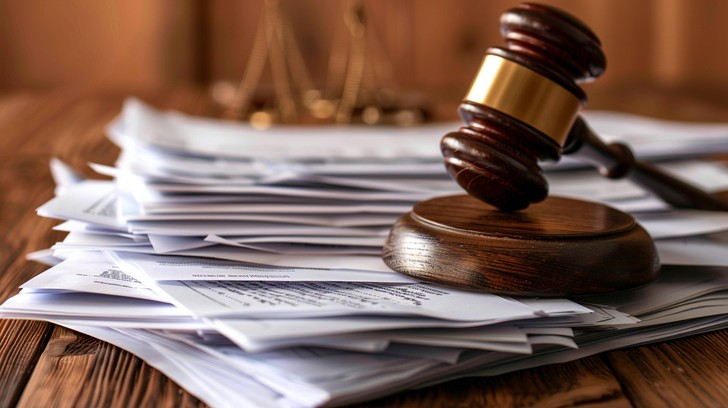


<div style="background-color:#1e2a44; background-image:linear-gradient(135deg,#1a73e8 0%,#1e2a44 60%,#9334e6 100%); color:#ffffff; text-align:center; padding:30px 24px; border-radius:14px; margin:6px 0;">
<div style="font-size:13px; letter-spacing:3px; opacity:0.85;">NLP PROJECT</div>
<div style="font-size:30px; font-weight:bold; margin:10px 0 8px 0;">PII Detection &amp; Text Anonymization<br>in Legal Documents</div>
<div style="font-size:15px; opacity:0.9;">Detecting and masking personal information in court decisions — without making them useless</div>
<div style="margin-top:16px; font-size:13px;">
<span style="background-color:rgba(255,255,255,0.18); padding:4px 10px; border-radius:12px; margin:0 3px;">TAB dataset</span>
<span style="background-color:rgba(255,255,255,0.18); padding:4px 10px; border-radius:12px; margin:0 3px;">spaCy</span>
<span style="background-color:rgba(255,255,255,0.18); padding:4px 10px; border-radius:12px; margin:0 3px;">Logistic Regression</span>
<span style="background-color:rgba(255,255,255,0.18); padding:4px 10px; border-radius:12px; margin:0 3px;">BERT</span>
</div>
</div>


### Table of Contents

| | |
|---|---|
| 01. Introduction | 09. Baseline 2: Features + Logistic Regression |
| 02. Research Question | 10. Advanced Model: BERT |
| 03. State of the Art | 11. Results |
| 04. Dataset | 12. Error Analysis |
| 05. Data Preparation | 13. Interpretation of Results |
| 06. Methodology | 14. Limitations |
| 07. Evaluation Protocol | 15. Conclusion |
| 08. Baseline 1: spaCy NER | References |


## <span style="display:block; background-color:#1e2a44; color:#ffffff; padding:12px 18px; border-left:8px solid #1a73e8; border-radius:8px;">01 · INTRODUCTION</span>

Legal decisions are published for transparency, but they contain sensitive personal data that must be anonymized under privacy laws like the GDPR. Manual anonymization is slow and can't keep up with the volume of documents. NLP could automate this, but the real challenge isn't just detecting names — it's knowing which ones need hiding (e.g., a judge's name can stay, a victim's can't), and standard NER tools can't make that distinction.

## <span style="display:block; background-color:#1e2a44; color:#ffffff; padding:12px 18px; border-left:8px solid #d93025; border-radius:8px;">02 · RESEARCH QUESTION</span>

<div style="background-color:#fdecea; color:#202124; border-left:6px solid #d93025; padding:14px 18px; border-radius:6px; margin:10px 0;"><span style="font-size:17px;"><b>How can we automatically detect and anonymize personal information in legal documents — without making the text useless afterward?</b></span></div>

- **Context matters** → same entity type, different sensitivity (judge vs. victim)
- **Trade-off** → over-redact = lose legal value | under-redact = privacy violation


## <span style="display:block; background-color:#1e2a44; color:#ffffff; padding:12px 18px; border-left:8px solid #188038; border-radius:8px;">03 · STATE OF THE ART</span>

Existing anonymization approaches fall into four families, each improving on the previous one but leaving a key limitation:

| Approach | Example | Limitation |
|---|---|---|
| **Rules + NER toolkits** | Microsoft Presidio [9] | Poor generalization to new domains like legal text [1] |
| **Specialized PII models** | GLiNER2-PII [2] | Detects the entity *type*, not whether it should be hidden |
| **Legal fine-tuned models** | BERT trained on court cases [3] | People stay re-identifiable through indirect clues (dates, places) |
| **LLM-based anonymizers** | Staab et al. [4], Yang et al. [5], Loiseau et al. [6] | Costly, and sensitive data must be processed by large models |

<div style="background-color:#fdecea; color:#202124; border-left:6px solid #d93025; padding:14px 18px; border-radius:6px; margin:10px 0;"><b>New threat</b> → LLMs can now also <i>re-identify</i> people by combining scattered clues, including in court decisions [7], [8].</div>

<div style="background-color:#e6f4ea; color:#202124; border-left:6px solid #188038; padding:14px 18px; border-radius:6px; margin:10px 0;"><b>Gap</b> → No lightweight solution that both <b>understands context</b> (what really needs hiding) and <b>preserves document usefulness</b> in the legal domain. This is what our project targets.</div>


## <span style="display:block; background-color:#1e2a44; color:#ffffff; padding:12px 18px; border-left:8px solid #f9ab00; border-radius:8px;">04 · DATASET</span>

We use the **Text Anonymization Benchmark (TAB)**, a public corpus of **English court judgments** from the **European Court of Human Rights (ECHR)**, annotated specifically for anonymization.

### <span style="color:#f9ab00">▸ Why this dataset?</span>

- **Legal domain**: real court cases describing real people (applicants, witnesses, lawyers, officials).
- **Annotated for anonymization, not just NER**: each entity is labeled with whether it **must be masked or not**, which is exactly our research question.
- **High-quality labels**: annotated by **law students** following privacy guidelines inspired by the GDPR.
- **Ready for supervised learning**: the annotations serve as ground truth to train and evaluate our models.

### <span style="color:#f9ab00">▸ What it contains</span>

| | |
|---|---|
| **Documents** | 1,268 court judgments |
| **Annotated sections** | Introduction and Statement of Facts |
| **Entity mentions** | 155,006 |
| **Entity types** | PERSON, ORG, LOC, DATETIME, CODE, DEM, QUANTITY, MISC |
| **Masking labels** | `DIRECT` identifier, `QUASI` identifier, `NO_MASK` |
| **Format** | JSON (text + character-level annotations) |

### <span style="color:#f9ab00">▸ Data split</span>

| Split | Documents | Share |
|---|:---:|:---:|
| **Train** | 1,014 | 80% |
| **Validation** | 127 | 10% |
| **Test** | 127 | 10% |


## <span style="display:block; background-color:#1e2a44; color:#ffffff; padding:12px 18px; border-left:8px solid #9334e6; border-radius:8px;">05 · DATA PREPARATION</span>

Unlike classification tasks, anonymization requires keeping the **exact original text**: annotations are tied to character positions, and capitalization or small words ("the applicant", "his lawyer") are key clues. We therefore **do not** remove stopwords, lowercase, or lemmatize.

| Step | Goal |
|---|---|
| **1. Loading** | Read the TAB JSON files (text + annotations) |
| **2. Target definition** | Keep only entities that **must be masked** (`DIRECT` + `QUASI`), using one annotator per document |
| **3. BIO labeling** | Convert spans into token labels: `B-MASK` (beginning), `I-MASK` (inside), `O` (outside) |
| **4. Tokenization & alignment** | Split the text with a **cased** BERT tokenizer and align each token with its label |
| **5. Chunking** | Cut long documents into **512-token windows** with a **128-token overlap** so no entity is lost |

> *Example:* "Mr John Smith lives in Rome" → `O B-MASK I-MASK O O B-MASK`


In [1]:
# ============ Setup ============
!git clone -q https://github.com/NorskRegnesentral/text-anonymization-benchmark.git
!pip install -q transformers datasets

import json
from collections import Counter
from transformers import AutoTokenizer
from transformers.utils import logging
from datasets import Dataset, DatasetDict
logging.set_verbosity_error()   # hides the "longer than 512 tokens" warning

# ============ Step 1: Loading ============
DATA_DIR = "text-anonymization-benchmark"

def load_split(name):
    with open(f"{DATA_DIR}/echr_{name}.json", encoding="utf-8") as f:
        return json.load(f)

train_raw, dev_raw, test_raw = load_split("train"), load_split("dev"), load_split("test")
print(f"Train: {len(train_raw)} | Dev: {len(dev_raw)} | Test: {len(test_raw)} documents")

# ============ Step 2: Target definition ============
MASK_TYPES = {"DIRECT", "QUASI"}

def extract_documents(raw_docs):
    docs = []
    for doc in raw_docs:
        annotator = sorted(doc["annotations"].keys())[0]          # one annotator per document
        mentions = doc["annotations"][annotator]["entity_mentions"]
        spans = [(m["start_offset"], m["end_offset"])
                 for m in mentions if m["identifier_type"] in MASK_TYPES]
        docs.append({"doc_id": doc["doc_id"], "text": doc["text"], "spans": sorted(spans)})
    return docs

train_docs, dev_docs, test_docs = map(extract_documents, (train_raw, dev_raw, test_raw))

# ============ Step 3: BIO labeling ============
LABELS   = ["O", "B-MASK", "I-MASK"]
label2id = {label: i for i, label in enumerate(LABELS)}
id2label = {i: label for label, i in label2id.items()}

def char_labels(text, spans):
    tags = ["O"] * len(text)
    for start, end in spans:
        tags[start] = "B-MASK"
        for i in range(start + 1, end):
            tags[i] = "I-MASK"
    return tags

# ============ Steps 4 & 5: Tokenization, alignment, chunking ============
MODEL_NAME = "bert-base-cased"
MAX_LEN, STRIDE = 512, 128
BODY = MAX_LEN - 2          # room for [CLS] and [SEP]
STEP = BODY - STRIDE        # each new window starts 382 tokens later -> 128-token overlap
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_and_align(docs):
    out = {"input_ids": [], "attention_mask": [], "labels": []}
    for doc in docs:
        tags = char_labels(doc["text"], doc["spans"])

        # 1) Tokenize the whole document (no truncation) and label each token
        enc = tokenizer(doc["text"], add_special_tokens=False, return_offsets_mapping=True)
        labels, prev_word, prev_tag = [], None, "O"
        for word_id, (start, end) in zip(enc.word_ids(), enc["offset_mapping"]):
            if word_id == prev_word:                          # sub-word piece -> ignored
                labels.append(-100)
            else:
                tag = tags[start]
                if tag == "I-MASK" and prev_tag == "O":       # entity starting mid-word
                    tag = "B-MASK"
                labels.append(label2id[tag])
                prev_tag = tag
            prev_word = word_id

        # 2) Cut into overlapping windows of 512 tokens
        ids = enc["input_ids"]
        for s in range(0, max(len(ids) - STRIDE, 1), STEP):
            win_ids, win_labels = ids[s:s + BODY], labels[s:s + BODY]
            out["input_ids"].append([tokenizer.cls_token_id] + win_ids + [tokenizer.sep_token_id])
            out["attention_mask"].append([1] * (len(win_ids) + 2))
            out["labels"].append([-100] + win_labels + [-100])
    return out

dataset = DatasetDict({
    "train":      Dataset.from_dict(tokenize_and_align(train_docs)),
    "validation": Dataset.from_dict(tokenize_and_align(dev_docs)),
    "test":       Dataset.from_dict(tokenize_and_align(test_docs)),
})
print(dataset)

# ============ Sanity check ============
sample = dataset["train"][0]
tokens = tokenizer.convert_ids_to_tokens(sample["input_ids"])
print("\nTokens to mask:", [(t, id2label[l]) for t, l in zip(tokens, sample["labels"]) if l > 0][:15])

counts = Counter(l for labels in dataset["train"]["labels"] for l in labels if l != -100)
print("Label distribution:", {id2label[k]: v for k, v in counts.items()})

Train: 1014 | Dev: 127 | Test: 127 documents


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 4771
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 395
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 378
    })
})

Tokens to mask: [('36', 'B-MASK'), ('/', 'I-MASK'), ('06', 'I-MASK'), ('Mr', 'B-MASK'), ('Henrik', 'I-MASK'), ('Has', 'I-MASK'), ('31', 'B-MASK'), ('August', 'I-MASK'), ('2006', 'I-MASK'), ('Mr', 'B-MASK'), ('Ty', 'I-MASK'), ('Tri', 'I-MASK'), ('Ms', 'B-MASK'), ('Nina', 'I-MASK'), ('Ho', 'I-MASK')]
Label distribution: {'O': 1803923, 'B-MASK': 74309, 'I-MASK': 148441}


### <span style="color:#f9ab00">▸ Dataset at a glance</span>


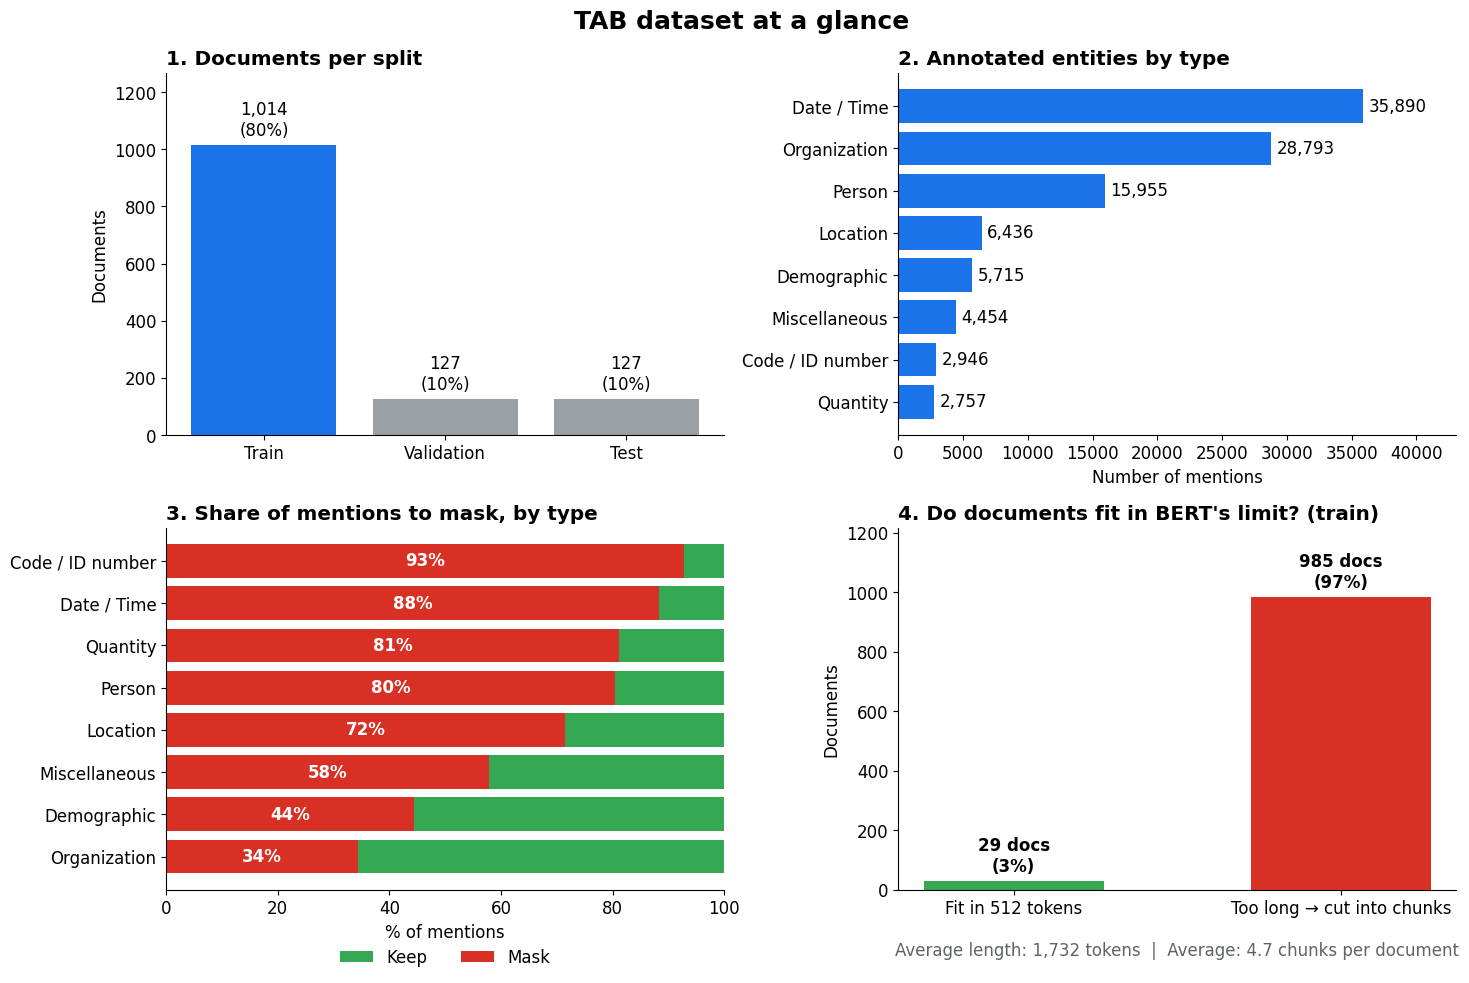

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from transformers.utils import logging
logging.set_verbosity_error()   # hides the "longer than 512" warning

plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, GREY = "#1a73e8", "#d93025", "#34a853", "#9aa0a6"

FULL_NAMES = {"DATETIME": "Date / Time", "ORG": "Organization", "PERSON": "Person",
              "LOC": "Location", "DEM": "Demographic", "MISC": "Miscellaneous",
              "CODE": "Code / ID number", "QUANTITY": "Quantity"}

# One row per annotated entity (first annotator, all splits)
rows = []
for split, raw in [("Train", train_raw), ("Validation", dev_raw), ("Test", test_raw)]:
    for d in raw:
        annotator = sorted(d["annotations"].keys())[0]
        for m in d["annotations"][annotator]["entity_mentions"]:
            rows.append({"split": split, "type": FULL_NAMES[m["entity_type"]],
                         "mask": m["identifier_type"] in ("DIRECT", "QUASI")})
df = pd.DataFrame(rows)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("TAB dataset at a glance", fontsize=18, fontweight="bold")

# 1. Documents per split
ax = axes[0, 0]
splits = {"Train": len(train_raw), "Validation": len(dev_raw), "Test": len(test_raw)}
bars = ax.bar(splits.keys(), splits.values(), color=[BLUE, GREY, GREY])
ax.bar_label(bars, labels=[f"{v:,}\n({v/sum(splits.values()):.0%})" for v in splits.values()], padding=4)
ax.set_title("1. Documents per split", fontweight="bold", loc="left")
ax.set_ylabel("Documents")
ax.set_ylim(0, max(splits.values()) * 1.25)

# 2. What kinds of entities are annotated?
ax = axes[0, 1]
counts = df["type"].value_counts().sort_values()
bars = ax.barh(counts.index, counts.values, color=BLUE)
ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values], padding=4)
ax.set_title("2. Annotated entities by type", fontweight="bold", loc="left")
ax.set_xlabel("Number of mentions")
ax.set_xlim(0, counts.max() * 1.2)

# 3. How often is each type masked?
ax = axes[1, 0]
rate = (df.groupby("type")["mask"].mean() * 100).sort_values()
ax.barh(rate.index, 100, color=GREEN, label="Keep")
bars = ax.barh(rate.index, rate.values, color=RED, label="Mask")
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in rate.values], label_type="center",
             color="white", fontweight="bold")
ax.set_title("3. Share of mentions to mask, by type", fontweight="bold", loc="left")
ax.set_xlabel("% of mentions")
ax.set_xlim(0, 100)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)

# 4. Do documents fit in BERT's 512-token limit?
ax = axes[1, 1]
lengths = [len(tokenizer(d["text"], add_special_tokens=False)["input_ids"]) for d in train_docs]
fits = sum(L <= BODY for L in lengths)
too_long = len(lengths) - fits
bars = ax.bar(["Fit in 512 tokens", "Too long → cut into chunks"], [fits, too_long],
              color=[GREEN, RED], width=0.55)
ax.bar_label(bars, labels=[f"{v:,} docs\n({v/len(lengths):.0%})" for v in (fits, too_long)],
             padding=4, fontweight="bold")
ax.set_title("4. Do documents fit in BERT's limit? (train)", fontweight="bold", loc="left")
ax.set_ylabel("Documents")
ax.set_ylim(0, len(lengths) * 1.2)
ax.text(0.5, -0.18, f"Average length: {sum(lengths)/len(lengths):,.0f} tokens  |  "
        f"Average: {len(dataset['train'])/len(train_docs):.1f} chunks per document",
        transform=ax.transAxes, ha="center", fontsize=12, color="#5f6368")

plt.tight_layout()
plt.show()

## <span style="display:block; background-color:#1e2a44; color:#ffffff; padding:12px 18px; border-left:8px solid #1a73e8; border-radius:8px;">06 · METHODOLOGY</span>

We treat anonymization as a **token classification** task: for each word, the model predicts `B-MASK`, `I-MASK` or `O`. The predicted entities are then replaced by `[MASKED]`.

To show that **context** is needed, we compare three models of increasing complexity, all evaluated on the **same test set** with the **same metrics**:

| Step | Model | What it tests |
|---|---|---|
| **Baseline 1** | spaCy NER, masks **every** detected entity | Is detecting entities enough? (no context, no training) |
| **Baseline 2** | Hand-crafted features + Logistic Regression | Can a classic ML model learn *which* entities to mask? |
| **Advanced model** | BERT fine-tuned on TAB | Does deep contextual understanding improve decisions? |

<div style="background-color:#f1f5fe; color:#202124; border-left:6px solid #1a73e8; padding:14px 18px; border-radius:6px; margin:10px 0;"><b>Pipeline:</b> Preprocessing → Baselines → BERT fine-tuning → Evaluation on the test set → Error analysis</div>

**Evaluation** measures both sides of our research question:
- **Privacy**: are the identifiers really hidden?
- **Utility**: are the entities that should stay visible left untouched?

## <span style="display:block; background-color:#1e2a44; color:#ffffff; padding:12px 18px; border-left:8px solid #d93025; border-radius:8px;">07 · EVALUATION PROTOCOL</span>

All models are evaluated on the **127 test documents**, at the **word level** (the same word segmentation for every model, so the comparison is fair).

| Metric | Question it answers |
|---|---|
| **Accuracy** | % of words with the correct label. *Misleading here: 89% of words are `O`, so a model that masks nothing already scores ~89%.* |
| **Precision** | Of the entities the model masked, how many were correct? |
| **Recall** | Of the entities that had to be masked, how many did the model find? |
| **F1** | Balance between precision and recall (main detection metric) |
| **Privacy** | % of identifiers (DIRECT + QUASI) **fully** masked. One visible piece is enough to re-identify someone. |
| **Utility loss** | % of entities that should be **kept** (NO_MASK) but were masked. Over-masking destroys the document's value. |

Precision, recall and F1 are computed at the **entity level**: an entity counts as correct only if its boundaries match exactly.


### <span style="color:#d93025">▸ Evaluation functions</span>


In [3]:
import re
import numpy as np
import pandas as pd

WORD_RE = re.compile(r"\w+|[^\w\s]")          # common word segmentation for all models
FULL_NAMES = {"DATETIME": "Date / Time", "ORG": "Organization", "PERSON": "Person",
              "LOC": "Location", "DEM": "Demographic", "MISC": "Miscellaneous",
              "CODE": "Code / ID number", "QUANTITY": "Quantity"}

def words_of(text):
    """Word boundaries (start, end) used to compare all models on the same units."""
    return [(m.start(), m.end()) for m in WORD_RE.finditer(text)]

def word_bio(text, spans):
    """BIO label of each word, given character spans to mask."""
    tags, out, prev = char_labels(text, spans), [], "O"
    for start, _ in words_of(text):
        tag = tags[start]
        if tag == "I-MASK" and prev == "O":
            tag = "B-MASK"
        out.append(tag)
        prev = tag
    return out

def bio_to_spans(offsets, labels):
    """Turn word-level BIO predictions back into character spans."""
    spans, cur = [], None
    for (start, end), label in zip(offsets, labels):
        if label == "B-MASK" or (label == "I-MASK" and cur is None):
            if cur: spans.append(tuple(cur))
            cur = [start, end]
        elif label == "I-MASK":
            cur[1] = end
        else:
            if cur: spans.append(tuple(cur))
            cur = None
    if cur: spans.append(tuple(cur))
    return spans

def entities(labels):
    """Set of (start, end) word-index entities in a BIO sequence."""
    ents, start = set(), None
    for i, label in enumerate(labels + ["O"]):
        if start is not None and label != "I-MASK":
            ents.add((start, i)); start = None
        if label == "B-MASK" or (label == "I-MASK" and start is None):
            start = i
    return ents

def prf(true_seqs, pred_seqs):
    """Entity-level precision / recall / F1 (exact span match)."""
    tp = n_pred = n_true = 0
    for t, p in zip(true_seqs, pred_seqs):
        et, ep = entities(t), entities(p)
        tp += len(et & ep); n_pred += len(ep); n_true += len(et)
    precision = tp / n_pred if n_pred else 0.0
    recall = tp / n_true if n_true else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return precision, recall, f1

def mention_table(raw_docs, pred_spans):
    """One row per annotated mention: was it masked by the model?"""
    rows = []
    for doc, spans in zip(raw_docs, pred_spans):
        text = doc["text"]
        mask = np.zeros(len(text), dtype=bool)
        for s, e in spans:
            mask[s:e] = True
        annotator = sorted(doc["annotations"].keys())[0]
        for m in doc["annotations"][annotator]["entity_mentions"]:
            idx = [i for i in range(m["start_offset"], m["end_offset"]) if not text[i].isspace()]
            rows.append({"doc_id": doc["doc_id"], "text": m["span_text"],
                         "type": FULL_NAMES[m["entity_type"]], "decision": m["identifier_type"],
                         "fully_masked": bool(mask[idx].all()), "partly_masked": bool(mask[idx].any())})
    return pd.DataFrame(rows)

def evaluate(name, raw_docs, docs, pred_spans):
    y_true = [word_bio(d["text"], d["spans"]) for d in docs]
    y_pred = [word_bio(d["text"], p) for d, p in zip(docs, pred_spans)]
    accuracy = np.mean([t == p for ts, ps in zip(y_true, y_pred) for t, p in zip(ts, ps)])
    precision, recall, f1 = prf(y_true, y_pred)
    mentions = mention_table(raw_docs, pred_spans)
    to_mask = mentions[mentions["decision"] != "NO_MASK"]
    to_keep = mentions[mentions["decision"] == "NO_MASK"]
    return {"Model": name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "Privacy: identifiers fully masked": to_mask["fully_masked"].mean(),
            "Utility: NO_MASK wrongly masked": to_keep["partly_masked"].mean()}

results = []

## <span style="display:block; background-color:#1e2a44; color:#ffffff; padding:12px 18px; border-left:8px solid #9aa0a6; border-radius:8px;">08 · BASELINE 1: spaCy NER (mask everything)</span>

The simplest possible approach, and the one used by generic tools like Presidio: detect named entities with a pretrained NER model and **mask all of them**. No training on TAB, no notion of context. This baseline tests our hypothesis that **detecting entities is not the same as deciding what to hide**.


In [4]:
!python -m spacy download en_core_web_sm -q
import spacy

nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])
nlp.max_length = 2_000_000

def spacy_predict(docs):
    return [[(ent.start_char, ent.end_char) for ent in doc.ents]
            for doc in nlp.pipe((d["text"] for d in docs), batch_size=8)]

spacy_spans = spacy_predict(test_docs)
results.append(evaluate("Baseline 1: spaCy NER (mask all)", test_raw, test_docs, spacy_spans))
pd.DataFrame(results).set_index("Model").round(3)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 114.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


,Accuracy,Precision,Recall,F1,Privacy: identifiers fully masked,Utility: NO_MASK wrongly masked
Model,,,,,,
Baseline 1: spaCy NER (mask all),0.847,0.327,0.67,0.439,0.762,0.854


## <span style="display:block; background-color:#1e2a44; color:#ffffff; padding:12px 18px; border-left:8px solid #f9ab00; border-radius:8px;">09 · BASELINE 2: Features + Logistic Regression</span>

A classic machine learning model trained on TAB. **Why not TF-IDF?** TF-IDF gives one weight per word for a whole document, so it can tell *which* words matter in a document, but not *where* an entity starts and ends. Our task needs one decision **per word**, so we use the token-level equivalent: each word is described by hand-crafted features, and a Logistic Regression predicts its BIO label.

| Feature | Why it helps |
|---|---|
| The word itself (lowercased) | Some words are almost always identifiers |
| Word shape (`Xxx`, `dd/dd`) | Names are capitalized, case numbers have a fixed pattern |
| Suffix (last 3 letters) | Nationalities ("-ish", "-ian"), place names |
| Capitalization / digits | Strong signals for names and dates |
| **2 words before and after** | A small window of **context** ("Mr ___", "born on ___") |


In [5]:
import warnings
from sklearn.feature_extraction import FeatureHasher
from sklearn.linear_model import SGDClassifier
from scipy.sparse import vstack
warnings.filterwarnings("ignore")

def shape(w):
    s = re.sub(r"[A-Z]", "X", re.sub(r"[a-z]", "x", re.sub(r"\d", "d", w)))
    return re.sub(r"(.)\1+", r"\1\1", s)          # "Xxxxxx" -> "Xxx"

def word_features(words, i):
    w = words[i]
    feats = {"w=" + w.lower(): 1, "shape=" + shape(w): 1, "suf=" + w[-3:].lower(): 1,
             "title": w.istitle(), "upper": w.isupper(), "digit": w.isdigit()}
    for k in (-2, -1, 1, 2):                       # context window of 2 words on each side
        j = i + k
        c = words[j].lower() if 0 <= j < len(words) else "<pad>"
        feats[f"w[{k}]=" + c] = 1
    feats["prev_title"] = i > 0 and words[i - 1].istitle()
    return feats

def doc_features(doc):
    offsets = words_of(doc["text"])
    words = [doc["text"][s:e] for s, e in offsets]
    return offsets, [word_features(words, i) for i in range(len(words))]

hasher = FeatureHasher(n_features=2**20, input_type="dict")

X_parts, y = [], []
for d in train_docs:
    _, feats = doc_features(d)
    X_parts.append(hasher.transform(feats))
    y += word_bio(d["text"], d["spans"])
X_train = vstack(X_parts)
print("Training words:", X_train.shape[0])

clf = SGDClassifier(loss="log_loss", alpha=1e-6, max_iter=20, random_state=42)   # logistic regression
clf.fit(X_train, y)

def ml_predict(docs):
    all_spans = []
    for d in docs:
        offsets, feats = doc_features(d)
        labels = clf.predict(hasher.transform(feats))
        all_spans.append(bio_to_spans(offsets, labels))
    return all_spans

ml_spans = ml_predict(test_docs)
results.append(evaluate("Baseline 2: Features + Logistic Regression", test_raw, test_docs, ml_spans))
pd.DataFrame(results).set_index("Model").round(3)

Training words: 1588534


,Accuracy,Precision,Recall,F1,Privacy: identifiers fully masked,Utility: NO_MASK wrongly masked
Model,,,,,,
Baseline 1: spaCy NER (mask all),0.847,0.327,0.670,0.439,0.762,0.854
Baseline 2: Features + Logistic Regression,0.963,0.697,0.732,0.714,0.748,0.225


## <span style="display:block; background-color:#1e2a44; color:#ffffff; padding:12px 18px; border-left:8px solid #1a73e8; border-radius:8px;">10 · ADVANCED MODEL: BERT</span>

### <span style="color:#1a73e8">▸ Why BERT?</span>
- **Bidirectional context**: BERT reads the whole window at once, before and after each word, which is exactly what is needed to tell a judge from a victim.
- **Pretrained**: it already understands English, so it only has to learn *what to mask*, which works well with our 1,014 training documents.
- **Standard for token classification** (NER), and fits in a free Colab GPU.

### <span style="color:#1a73e8">▸ Why `bert-base-cased` and not another model?</span>

| Candidate | Why not chosen |
|---|---|
| `bert-base-uncased` / LEGAL-BERT | **Lowercase** models: they lose capitalization, a key clue for names |
| Longformer (used in the TAB paper) | Reads 4,096 tokens, but too heavy for a free Colab GPU |
| **`bert-base-cased` (selected)** | Keeps capitalization, well documented, trainable in ~30 min on a T4 GPU |

### <span style="color:#1a73e8">▸ Fine-tuning: chosen hyperparameters</span>

| Parameter | Value | Justification |
|---|---|---|
| Learning rate | 3e-5 | Middle of the range recommended by the BERT authors (2e-5 to 5e-5); small enough not to erase pretrained knowledge |
| Batch size | 8 × 2 accumulation = **16** | 512-token windows are memory-heavy; accumulation gives an effective batch of 16 |
| Epochs | 3 | Recommended range is 2 to 4; more risks overfitting |
| Warmup | 10% of steps | Starts with a small learning rate to stabilize early training |
| Weight decay | 0.01 | Light regularization against overfitting |
| Model selection | Best **validation F1** | We keep the epoch that performs best on unseen data |
| Mixed precision (fp16) | On | About 2x faster on GPU |


### <span style="color:#1a73e8">▸ Fine-tuning BERT</span>


In [6]:
import torch
from transformers import (AutoModelForTokenClassification, TrainingArguments,
                          Trainer, DataCollatorForTokenClassification)

print("GPU available:", torch.cuda.is_available())

model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LABELS), id2label=id2label, label2id=label2id)

def compute_metrics(eval_pred):
    """Entity-level F1 on the validation windows, used to pick the best epoch."""
    logits, label_ids = eval_pred
    preds = logits.argmax(-1)
    true_seqs, pred_seqs = [], []
    for p_row, l_row in zip(preds, label_ids):
        keep = l_row != -100                          # ignore special tokens and sub-words
        true_seqs.append([id2label[l] for l in l_row[keep]])
        pred_seqs.append([id2label[p] for p in p_row[keep]])
    precision, recall, f1 = prf(true_seqs, pred_seqs)
    return {"precision": precision, "recall": recall, "f1": f1}

EPOCHS, BATCH, ACCUM = 3, 8, 2
total_steps = (len(dataset["train"]) // (BATCH * ACCUM)) * EPOCHS

args = TrainingArguments(
    output_dir="bert-tab",
    learning_rate=3e-5,
    per_device_train_batch_size=BATCH,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=ACCUM,
    num_train_epochs=EPOCHS,
    weight_decay=0.01,
    warmup_steps=int(0.1 * total_steps),
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    save_total_limit=1,
    fp16=torch.cuda.is_available(),
    logging_steps=50,
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=dataset["train"],
    eval_dataset=dataset["validation"],
    data_collator=DataCollatorForTokenClassification(tokenizer),   # pads windows to the same length
    compute_metrics=compute_metrics,
)
trainer.train()

GPU available: True


model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.115', 'grad_norm': '0.7081', 'learning_rate': '1.652e-05', 'epoch': '0.1675'}
{'loss': '0.2639', 'grad_norm': '0.9147', 'learning_rate': '2.963e-05', 'epoch': '0.335'}
{'loss': '0.2364', 'grad_norm': '0.4405', 'learning_rate': '2.777e-05', 'epoch': '0.5025'}
{'loss': '0.2194', 'grad_norm': '0.5821', 'learning_rate': '2.592e-05', 'epoch': '0.67'}
{'loss': '0.1933', 'grad_norm': '0.6467', 'learning_rate': '2.406e-05', 'epoch': '0.8375'}
{'eval_loss': '0.09873', 'eval_precision': '0.7163', 'eval_recall': '0.7447', 'eval_f1': '0.7302', 'eval_runtime': '3.785', 'eval_samples_per_second': '104.4', 'eval_steps_per_second': '6.605', 'epoch': '1'}


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.1553', 'grad_norm': '0.558', 'learning_rate': '1.106e-05', 'epoch': '2.007'}
{'loss': '0.1533', 'grad_norm': '0.7772', 'learning_rate': '9.208e-06', 'epoch': '2.174'}
{'loss': '0.143', 'grad_norm': '0.5064', 'learning_rate': '7.351e-06', 'epoch': '2.342'}
{'loss': '0.1318', 'grad_norm': '0.5985', 'learning_rate': '5.495e-06', 'epoch': '2.509'}
{'loss': '0.1309', 'grad_norm': '0.5898', 'learning_rate': '3.639e-06', 'epoch': '2.677'}
{'loss': '0.1413', 'grad_norm': '0.6502', 'learning_rate': '1.782e-06', 'epoch': '2.844'}
{'eval_loss': '0.096', 'eval_precision': '0.7257', 'eval_recall': '0.7697', 'eval_f1': '0.7471', 'eval_runtime': '3.751', 'eval_samples_per_second': '105.3', 'eval_steps_per_second': '6.665', 'epoch': '3'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '493.9', 'train_samples_per_second': '28.98', 'train_steps_per_second': '1.816', 'train_loss': '0.2253', 'epoch': '3'}


TrainOutput(global_step=897, training_loss=0.22529392922868166, metrics={'train_runtime': 493.9134, 'train_samples_per_second': 28.979, 'train_steps_per_second': 1.816, 'train_loss': 0.22529392922868166, 'epoch': 3.0})

### <span style="color:#1a73e8">▸ Training curves</span>


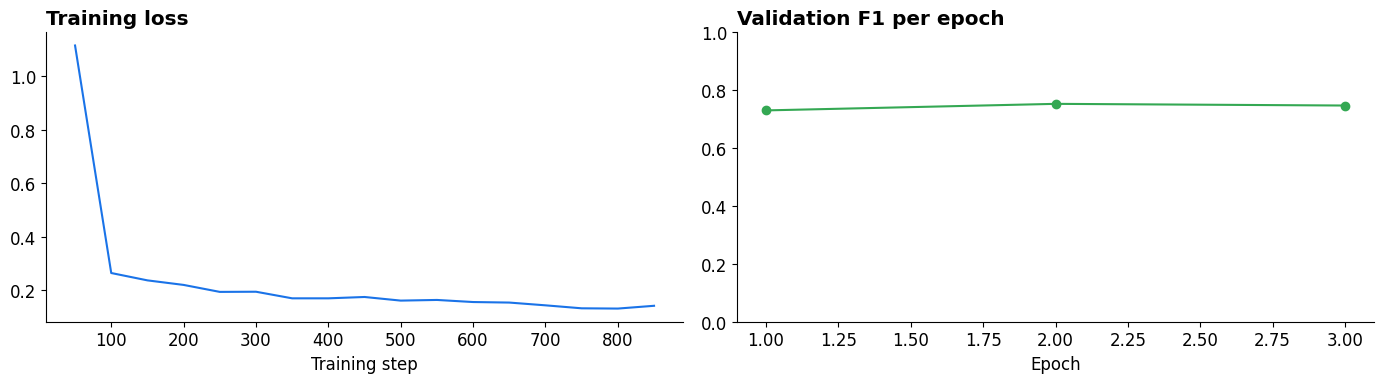

In [7]:
# Training curves
import matplotlib.pyplot as plt

log = pd.DataFrame(trainer.state.log_history)
train_log = log.dropna(subset=["loss"])
val_log = log.dropna(subset=["eval_f1"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(train_log["step"], train_log["loss"], color="#1a73e8")
ax1.set_title("Training loss", fontweight="bold", loc="left")
ax1.set_xlabel("Training step")
ax2.plot(val_log["epoch"], val_log["eval_f1"], marker="o", color="#34a853")
ax2.set_title("Validation F1 per epoch", fontweight="bold", loc="left")
ax2.set_xlabel("Epoch")
ax2.set_ylim(0, 1)
plt.tight_layout()
plt.show()

### <span style="color:#1a73e8">▸ Predicting on full documents</span>
BERT predicts on 512-token windows, so each test document is cut the same way as during training. Where two windows overlap, the model's scores are **averaged**, and each word takes the label of its first sub-word. The labels are then converted back into character spans.


In [8]:
def bert_predict(docs, batch_size=16):
    model.eval()
    all_spans = []
    for d in docs:
        enc = tokenizer(d["text"], add_special_tokens=False, return_offsets_mapping=True)
        ids, n = enc["input_ids"], len(enc["input_ids"])
        logit_sum, counts = np.zeros((n, len(LABELS))), np.zeros(n)
        starts = list(range(0, max(n - STRIDE, 1), STEP))

        # 1) Run BERT on each 512-token window
        for b in range(0, len(starts), batch_size):
            batch_starts = starts[b:b + batch_size]
            windows = [[tokenizer.cls_token_id] + ids[s:s + BODY] + [tokenizer.sep_token_id] for s in batch_starts]
            width = max(len(w) for w in windows)
            input_ids = torch.tensor([w + [tokenizer.pad_token_id] * (width - len(w)) for w in windows], device=model.device)
            attention = torch.tensor([[1] * len(w) + [0] * (width - len(w)) for w in windows], device=model.device)
            with torch.no_grad():
                logits = model(input_ids=input_ids, attention_mask=attention).logits.float().cpu().numpy()
            # 2) Put window scores back in document order (overlaps are averaged)
            for k, s in enumerate(batch_starts):
                L = len(windows[k]) - 2
                logit_sum[s:s + L] += logits[k, 1:L + 1]
                counts[s:s + L] += 1
        token_pred = (logit_sum / counts[:, None]).argmax(-1)

        # 3) One label per word (its first sub-token), then back to character spans
        offsets, labels, seen = [], [], set()
        for t, w in enumerate(enc.word_ids()):
            if w in seen:
                continue
            seen.add(w)
            span = enc.word_to_chars(w)
            offsets.append((span.start, span.end))
            labels.append(id2label[token_pred[t]])
        all_spans.append(bio_to_spans(offsets, labels))
    return all_spans

bert_spans = bert_predict(test_docs)
results.append(evaluate("Advanced model: BERT fine-tuned", test_raw, test_docs, bert_spans))
pd.DataFrame(results).set_index("Model").round(3)

,Accuracy,Precision,Recall,F1,Privacy: identifiers fully masked,Utility: NO_MASK wrongly masked
Model,,,,,,
Baseline 1: spaCy NER (mask all),0.847,0.327,0.670,0.439,0.762,0.854
Baseline 2: Features + Logistic Regression,0.963,0.697,0.732,0.714,0.748,0.225
Advanced model: BERT fine-tuned,0.972,0.798,0.816,0.807,0.846,0.189


## <span style="display:block; background-color:#1e2a44; color:#ffffff; padding:12px 18px; border-left:8px solid #34a853; border-radius:8px;">11 · RESULTS</span>
Comparison of the three models on the test set.


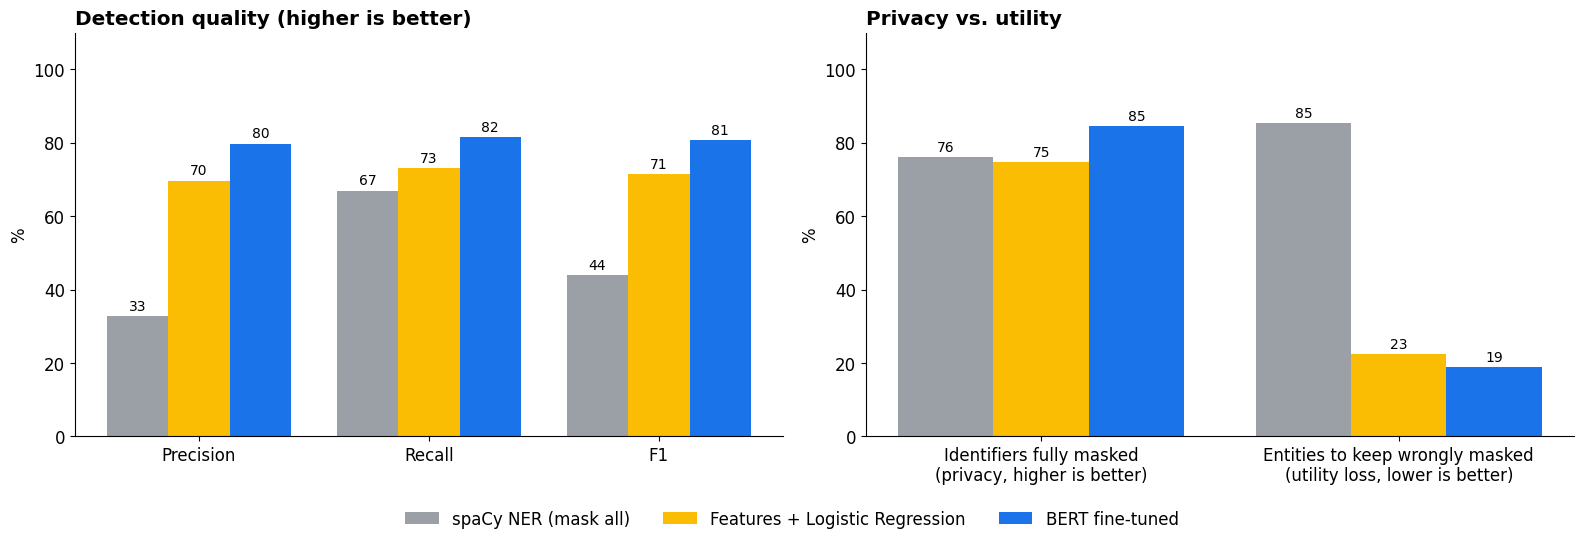

,Accuracy,Precision,Recall,F1,Privacy: identifiers fully masked,Utility: NO_MASK wrongly masked
spaCy NER (mask all),0.847,0.327,0.670,0.439,0.762,0.854
Features + Logistic Regression,0.963,0.697,0.732,0.714,0.748,0.225
BERT fine-tuned,0.972,0.798,0.816,0.807,0.846,0.189


In [9]:
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

res = pd.DataFrame(results).set_index("Model")
res.index = [m.split(": ")[1] for m in res.index]           # short names for the charts
COLORS = ["#9aa0a6", "#fbbc04", "#1a73e8"][:len(res)]

def grouped_bars(ax, metrics, labels, title):
    x, w = np.arange(len(metrics)), 0.8 / len(res)
    for i, (name, row) in enumerate(res.iterrows()):
        bars = ax.bar(x + i * w, row[metrics] * 100, w, label=name, color=COLORS[i])
        ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=10)
    ax.set_xticks(x + w * (len(res) - 1) / 2, labels)
    ax.set_ylim(0, 110)
    ax.set_ylabel("%")
    ax.set_title(title, fontweight="bold", loc="left")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))
grouped_bars(ax1, ["Precision", "Recall", "F1"], ["Precision", "Recall", "F1"],
             "Detection quality (higher is better)")
grouped_bars(ax2, ["Privacy: identifiers fully masked", "Utility: NO_MASK wrongly masked"],
             ["Identifiers fully masked\n(privacy, higher is better)",
              "Entities to keep wrongly masked\n(utility loss, lower is better)"],
             "Privacy vs. utility")
fig.legend(*ax1.get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

res.round(3)

## <span style="display:block; background-color:#1e2a44; color:#ffffff; padding:12px 18px; border-left:8px solid #9334e6; border-radius:8px;">12 · ERROR ANALYSIS</span>

We look at two kinds of errors:
- **Privacy errors**: identifiers the model failed to mask. Which entity types are hardest?
- **Utility errors**: entities that should be kept but were masked. Did the model learn context, compared to spaCy which masks everything?


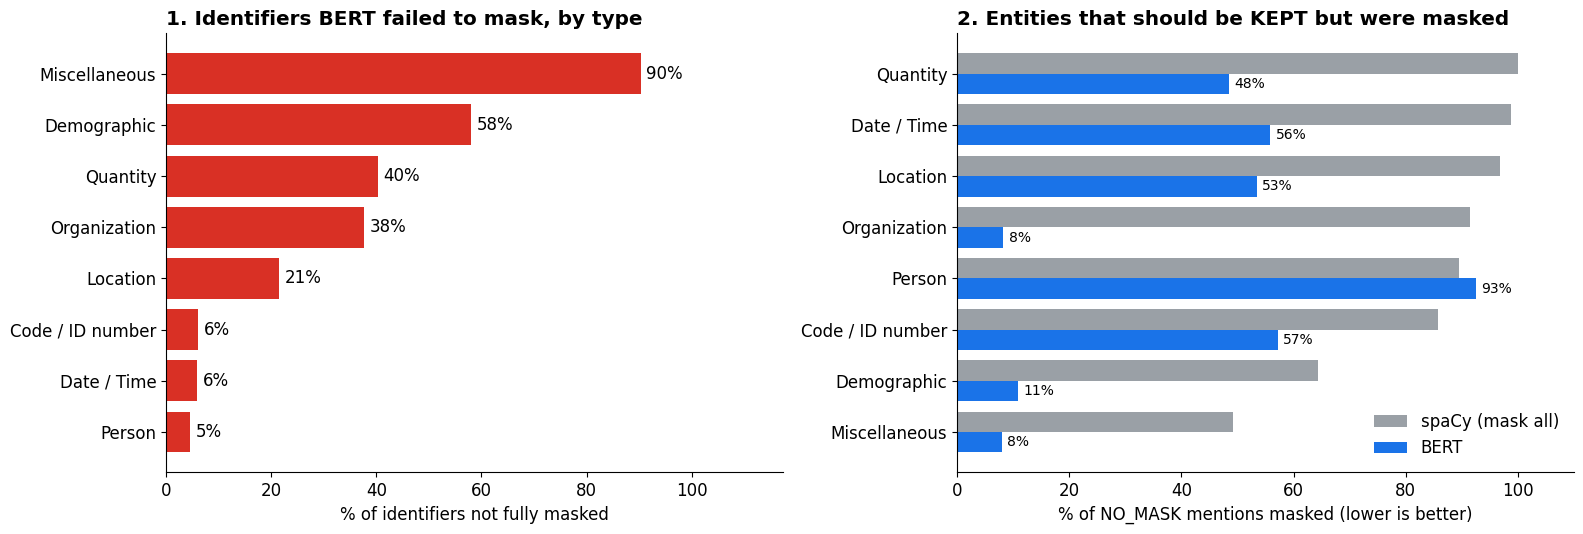

In [10]:
bert_mentions  = mention_table(test_raw, bert_spans)
spacy_mentions = mention_table(test_raw, spacy_spans)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

# 1. Which identifiers does BERT miss?
to_mask = bert_mentions[bert_mentions["decision"] != "NO_MASK"]
missed = (1 - to_mask.groupby("type")["fully_masked"].mean()).sort_values() * 100
bars = ax1.barh(missed.index, missed.values, color="#d93025")
ax1.bar_label(bars, fmt="%.0f%%", padding=4)
ax1.set_title("1. Identifiers BERT failed to mask, by type", fontweight="bold", loc="left")
ax1.set_xlabel("% of identifiers not fully masked")
ax1.set_xlim(0, max(missed.max() * 1.3, 10))

# 2. Does BERT use context? Over-masking of entities that should be kept
keep_bert  = bert_mentions[bert_mentions["decision"] == "NO_MASK"].groupby("type")["partly_masked"].mean() * 100
keep_spacy = spacy_mentions[spacy_mentions["decision"] == "NO_MASK"].groupby("type")["partly_masked"].mean() * 100
order = keep_spacy.sort_values().index
y = np.arange(len(order))
ax2.barh(y + 0.2, keep_spacy[order], 0.4, color="#9aa0a6", label="spaCy (mask all)")
bars = ax2.barh(y - 0.2, keep_bert.reindex(order).fillna(0), 0.4, color="#1a73e8", label="BERT")
ax2.bar_label(bars, fmt="%.0f%%", padding=4, fontsize=10)
ax2.set_yticks(y, order)
ax2.set_xlim(0, 110)
ax2.set_title("2. Entities that should be KEPT but were masked", fontweight="bold", loc="left")
ax2.set_xlabel("% of NO_MASK mentions masked (lower is better)")
ax2.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.show()

## <span style="display:block; background-color:#1e2a44; color:#ffffff; padding:12px 18px; border-left:8px solid #34a853; border-radius:8px;">13 · INTERPRETATION OF RESULTS</span>

| Model | Precision | Recall | F1 | Identifiers masked ↑ | Kept entities wrongly masked ↓ |
|---|---|---|---|---|---|
| spaCy NER (mask all) | 0.33 | 0.67 | 0.44 | 76% | 85% |
| Features + Logistic Regression | 0.70 | 0.73 | 0.71 | 75% | 23% |
| **BERT fine-tuned** | **0.80** | **0.82** | **0.81** | **85%** | **19%** |

- **Accuracy is not reliable here:** 89% of words don't need masking, so even a model that masks nothing scores high.
- **spaCy** masks almost everything, including 85% of the entities that should stay visible. Detecting entities is not enough.
- **Logistic Regression** learns from TAB which entities to keep: over-masking drops from 85% to 23%.
- **BERT** is the best on every metric. It protects more identifiers (85%) **and** masks fewer entities by mistake (19%), which shows that **context is the key**.

**Error analysis**
- BERT rarely misses clear identifiers (persons, dates, codes: ~5%), but misses vague ones like Miscellaneous (90%) and Demographic (58%).
- It learned to keep organizations and demographics visible, but still masks **93% of person names that should be kept**. Telling a public person from a private one remains the hardest part.


## <span style="display:block; background-color:#1e2a44; color:#ffffff; padding:12px 18px; border-left:8px solid #d93025; border-radius:8px;">14 · LIMITATIONS</span>

- **One annotator only:** other annotators might have made different, valid choices.
- **Inconsistent annotations:** the same person can be "keep" in one document and "mask" in another, which makes persons hard to learn.
- **Limited context:** BERT reads 512 tokens at a time, so it can miss a person's role explained earlier in the document.
- **Mentions handled separately:** missing one mention of a name is enough to re-identify someone.
- **One single training run**, with no hyperparameter search.
- **No re-identification test:** we didn't check whether people can still be identified after anonymization.

<div style="background-color:#e6f4ea; color:#202124; border-left:6px solid #188038; padding:14px 18px; border-radius:6px; margin:10px 0;"><b>Improvements:</b> a long-document model (Longformer), consistent masking of all mentions of the same person, and a re-identification attack to measure real privacy.</div>


## <span style="display:block; background-color:#1e2a44; color:#ffffff; padding:12px 18px; border-left:8px solid #1a73e8; border-radius:8px;">15 · CONCLUSION</span>

This project addressed a key challenge in publishing court decisions: **hiding personal information without making the documents useless**.

Using the TAB dataset of 1,268 European Court of Human Rights judgments, we compared three approaches of increasing complexity:

- **spaCy NER** detects entities but masks everything, destroying the document's value (85% of entities to keep were masked).
- **Logistic Regression**, trained on TAB, learns which entities to keep and greatly reduces over-masking.
- **BERT**, fine-tuned on TAB, gives the best results on every metric (F1 = 0.81), protecting **more** identifiers while masking **fewer** entities by mistake.

<div style="background-color:#f1f5fe; color:#202124; border-left:6px solid #1a73e8; padding:14px 18px; border-radius:6px; margin:10px 0;">These results confirm our main idea: <b>anonymization is not just about detecting entities, but about understanding context</b>.</div>

However, one challenge remains: BERT still struggles to tell a **public person** (judge, government agent) from a **private one**. Future work could use long-document models, mask all mentions of the same person consistently, and test privacy against re-identification attacks.


## <span style="display:block; background-color:#1e2a44; color:#ffffff; padding:12px 18px; border-left:8px solid #5f6368; border-radius:8px;">References</span>

[1] P. Jha, "PIIBench: A Unified Multi-Source Benchmark Corpus for Personally Identifiable Information Detection," *arXiv:2604.15776*, 2026.

[2] U. Zaratiana, A. Lewis, and G. Hurn-Maloney, "GLiNER2-PII: A Multilingual Model for Personally Identifiable Information Extraction," *arXiv:2605.09973*, 2026.

[3] I. Pilán et al., "The Text Anonymization Benchmark (TAB): A Dedicated Corpus and Evaluation Framework for Text Anonymization," *Computational Linguistics*, vol. 48, no. 4, pp. 1053–1101, 2022.

[4] R. Staab, M. Vero, M. Balunović, and M. Vechev, "Large Language Models are Advanced Anonymizers," *ICLR*, 2025.

[5] T. Yang, X. Zhu, and I. Gurevych, "Robust Utility-Preserving Text Anonymization Based on Large Language Models," *ACL*, pp. 28922–28941, 2025.

[6] G. Loiseau et al., "Adaptive Text Anonymization: Learning Privacy-Utility Trade-offs via Prompt Optimization," *Findings of ACL*, 2026.

[7] A. Nyffenegger, M. Stürmer, and J. Niklaus, "Anonymity at Risk? Assessing Re-Identification Capabilities of Large Language Models in Court Decisions," *Findings of NAACL*, 2024.

[8] Z. Li, J. Wen, and T. Li, "LLM Anonymization Against Agentic Re-Identification," *arXiv:2605.30848*, 2026.

[9] Microsoft, "Presidio: Data Protection and De-identification SDK." [Online]. Available: https://microsoft.github.io/presidio/

---

*Remark: this notebook was developed with the assistance of **Claude Opus 5.5** (Anthropic), used for literature research, concept explanations, and writing and debugging code. This model was chosen for its strength on complex, multi-step tasks combining research, NLP concepts and code. All experiments were run in this notebook, and the author remains responsible for the choices and interpretations.*
